# **Training & Evaluation — Vanilla RNN, Control (α = 0) vs Constrained (α = 1)**

1. **Predictions + labels + hidden activations** of the test trials
2. **2D trajectories** — original vs predicted
3. **Heatmaps** of the condition-averaged, peak-sorted activity
4. **RSM** matrices & plots
5. **Boxplot — Epochs** to the stopping criterion
6. **Boxplot — Correlation** between conditions

Existing models in `results/models` are reused, not retrained.

### **Paths**

In [1]:
##### paths: make src/ importable, and name the results folders
import sys, pathlib

ROOT    = pathlib.Path.cwd().parent
SRC     = ROOT / "src"
RESULTS = ROOT / "results"
MODELS_DIR  = RESULTS / "models"
FIGURES     = RESULTS / "figures"
DATA     = RESULTS / "data"
for d in (MODELS_DIR, FIGURES, DATA):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))

print("src     :", SRC)
print("models  :", MODELS_DIR)
print("figures :", FIGURES)
print("data :", DATA)

src     : /Users/kevin/Downloads/Github_Vanilla_RNN/src
models  : /Users/kevin/Downloads/Github_Vanilla_RNN/results/models
figures : /Users/kevin/Downloads/Github_Vanilla_RNN/results/figures
data : /Users/kevin/Downloads/Github_Vanilla_RNN/results/data


## **Configuration**

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from config import *        # constants, colours
from data import *          # build_data, make_loaders, split_indices
from model import *         # RNN, mse_loss, corr_penalty
from training import *      # train_run, run_study, ckpt_path
from loading import *       # load_ckpt, extract
from analysis import *      # compute_rsm, rsm, offdiag_mean_abs, first_crossing
from plotting import *      # plot_trajectories_2d, plot_sorted_averaged_activations, plot_rsm,
                            # paired_boxplot, plot_loss_curves, supp_figure

print_config(settings())
print("device:", DEV)

task:
      K: 5
      spacing_deg: 20
      num_steps: 132
      n_hold_origin: 16
      n_movement: 100
      n_hold_target: 16
      augmentation_factor: 13
      n_trials: 40960
      noise_level: 0.05
      sigma: 3
      input_mode: paper

model:
      hidden_units: 200
      rnn_alpha: 0.2
      rnn_noise: 0.2
      eval_noise: True
      rec_density: 0.8

training:
      alpha_penalty: 1.0
      penalty_reduce: sum
      learning_rate: 0.001
      grad_clip_norm: 0.2
      batch_size: 2000
      loss_t0: 0
      eval_t0: 0
      theta_stop: 0.06
      stop_patience: 5
      max_epochs: 2500
      seeds: [42, 123, 456, 777, 999, 2023, 31415, 271828, 7, 13]


device: cpu


### **Run-level knobs**

In [3]:
N_RUNS     = 1                     
RUN_SEEDS  = SEEDS[:N_RUNS]

print(f"{N_RUNS} run(s) x 2 networks | seeds {RUN_SEEDS} | <= {MAX_EPOCHS_BY_K[K_MAIN]} epochs | "
      f"batch {BATCH_SIZE} | K = {K_MAIN} | theta = {THETA_STOP} (patience {STOP_PATIENCE})")

1 run(s) x 2 networks | seeds [42] | <= 2500 epochs | batch 2000 | K = 5 | theta = 0.06 (patience 5)


## **Data**

In [4]:
D = build_data(K_MAIN)
L = make_loaders(D)
SPLITS = split_indices(D)
assert np.array_equal(SPLITS["test"], L["test_idx"]), "test split differs from the loaders"
IDX = SPLITS[SPLIT]
GO_STEP, T_TOTAL = D["GO_STEP"], D["T_TOTAL"]

print(f"K = {D['K']}   spacing = {SPACING_DEG} deg   endpoint angles = {np.round(D['theta_deg'], 2)}")
print(f"T = {T_TOTAL}   GO_STEP = {GO_STEP}   N_IN = {D['N_IN']}")

K = 5   spacing = 20 deg   endpoint angles = [130. 110.  90.  70.  50.]
T = 132   GO_STEP = 16   N_IN = 3


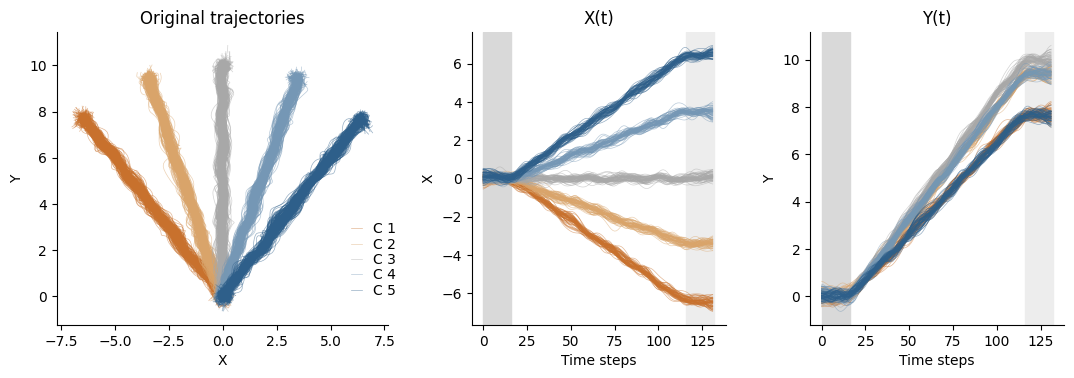

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1], "wspace": 0.3})
plot_trajectories_2d(axes[0], D["targ"][IDX], D["dirs"][IDX], title="Original trajectories",
                     legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.85, 0.05)})
t = np.arange(T_TOTAL)
for ax, dim, name in [(axes[1], 0, "X"), (axes[2], 1, "Y")]:
    for k in range(K_MAIN):
        rows = np.where(D["dirs"][IDX] == k)[0][:60]
        ax.plot(t, D["targ"][IDX][rows, :, dim].T, color=COLORS[k], lw=0.5, alpha=0.5)
    ax.axvspan(0, GO_STEP, color="0.85", zorder=0, label="Sampling")
    ax.axvspan(T_TOTAL - N_HOLD_TARGET, T_TOTAL, color="0.93", zorder=0, label="Reward")
    ax.set_xlabel("Time steps"); ax.set_ylabel(name); ax.set_title(f"{name}(t)")
    ax.spines[["top", "right"]].set_visible(False)
# axes[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(FIGURES / "data_trajectories.png", dpi=200, bbox_inches="tight")
plt.show()

## **Training**

In [6]:
import pickle

run_study(D, L, MODELS_DIR, seeds=RUN_SEEDS, conds=CONDS, print_every=100)
CKPTS = {c: [load_ckpt(ckpt_path(MODELS_DIR, K_MAIN, s, c)) for s in RUN_SEEDS] for c in CONDS}
for c in CONDS:
    for s, ck in zip(RUN_SEEDS, CKPTS[c]):
        print(f"{LAB[c]:12s} seed {s:6d} | stop epoch {ck['stop_epoch']:5d} | reached theta {ck['reached_theta']} | "
              f"test MSE {ck['test_mse']:.4f} | population |r| {ck['mean_abs_pearson_r']:.4f}")


2 cached, 0 to train.

finished in 0.0 min
Control      seed     42 | stop epoch    22 | reached theta True | test MSE 0.0427 | population |r| 0.7287
Constrained  seed     42 | stop epoch   341 | reached theta True | test MSE 0.0591 | population |r| 0.2094


## **1. Predictions with their labels & Hidden activations**

In [7]:
R = {c: extract(D, IDX, MODELS_DIR, SEED_FIG, c) for c in CONDS}

PREDICTIONS = {LAB[c]: R[c]["pred"] for c in CONDS}
HIDDEN      = {LAB[c]: R[c]["hidden"] for c in CONDS}
LABELS      = R["std"]["labels"]
assert np.array_equal(LABELS, R["con"]["labels"])

for name in PREDICTIONS:
    print(f"{name:12s} | predictions {PREDICTIONS[name].shape} | hidden {HIDDEN[name].shape}")
print(f"{'labels':12s} | {LABELS.shape} | values {np.unique(LABELS)}")
for c in CONDS:
    print(f"{LAB[c]:12s} | re-computed test MSE {R[c]['mse_batch']:.5f}  (stored {R[c]['ckpt']['test_mse']:.5f})")

Control      | predictions (8192, 132, 2) | hidden (8192, 200, 132)
Constrained  | predictions (8192, 132, 2) | hidden (8192, 200, 132)
labels       | (8192,) | values [0 1 2 3 4]
Control      | re-computed test MSE 0.04301  (stored 0.04270)
Constrained  | re-computed test MSE 0.05841  (stored 0.05906)


## **2. 2D trajectories of the predictions**

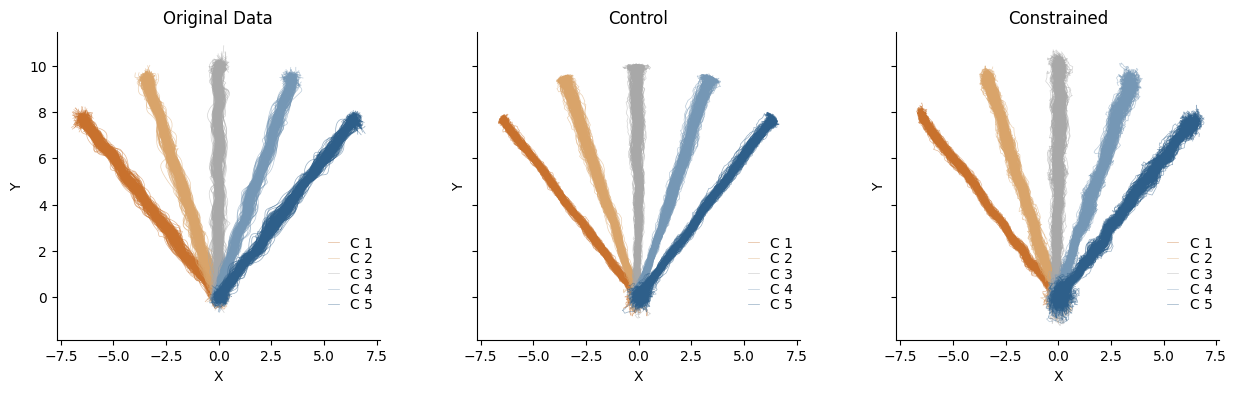

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.3)
lk = {"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)}
plot_trajectories_2d(axes[0], R["std"]["targ"], LABELS, title="Original Data", legend_kwargs=lk)
plot_trajectories_2d(axes[1], PREDICTIONS["Control"], LABELS, title="Control", legend_kwargs=lk)
plot_trajectories_2d(axes[2], PREDICTIONS["Constrained"], LABELS, title="Constrained", legend_kwargs=lk)
fig.savefig(FIGURES / f"trajectories_seed{SEED_FIG}.png", dpi=200, bbox_inches="tight")
plt.show()

## **3. Heatmaps**


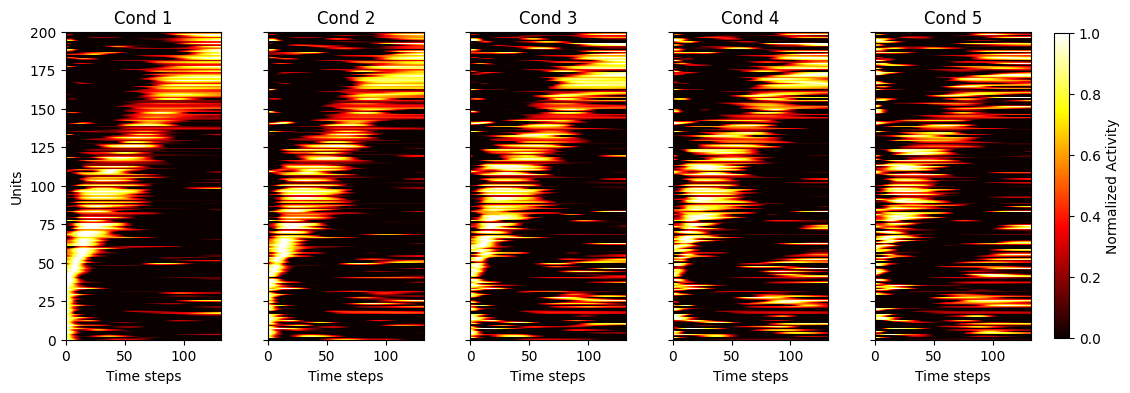

Control      | conditions [0, 1, 2, 3, 4] | averaged activity (5, 200, 132)


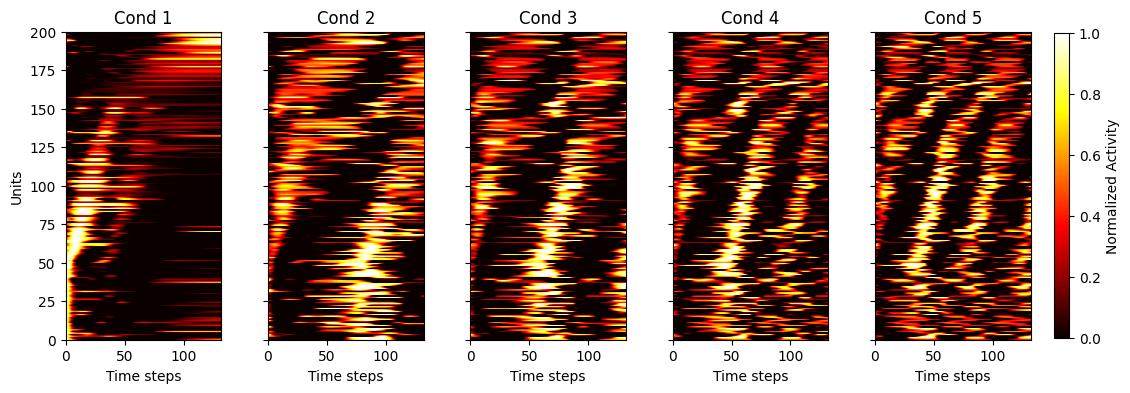

Constrained  | conditions [0, 1, 2, 3, 4] | averaged activity (5, 200, 132)


In [9]:
ACT = {}
vmin, vmax = HEATMAP_CLIM
for c in CONDS:
    fig, ax = plt.subplots(1, K_MAIN, figsize=(15, 4))
    Labels, ACT[LAB[c]] = plot_sorted_averaged_activations(ax, LABELS, HIDDEN[LAB[c]], vmin=0, vmax=1)
    # fig.suptitle(LAB[c], y=1.02, fontweight="bold")
    fig.savefig(FIGURES / f"heatmaps_{c}_seed{SEED_FIG}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"{LAB[c]:12s} | conditions {Labels} | averaged activity {ACT[LAB[c]].shape}")

## **4. RSM matrices & plots**

In [10]:
RSM = {name: compute_rsm(ACT[name]) for name in ACT}
for c in CONDS:
    name = LAB[c]
    print(f"{name:12s} | unit-wise RSM, mean off-diagonal |r| = {offdiag_mean_abs(RSM[name]):.3f}   "
          f"| population |r| = {offdiag_mean_abs(rsm(R[c]['hidden_dir_mean'])):.4f}")
    print(np.round(RSM[name], 3), "\n")

Control      | unit-wise RSM, mean off-diagonal |r| = 0.784   | population |r| = 0.7287
[[1.    0.902 0.764 0.647 0.555]
 [0.902 1.    0.913 0.782 0.652]
 [0.764 0.913 1.    0.933 0.777]
 [0.647 0.782 0.933 1.    0.909]
 [0.555 0.652 0.777 0.909 1.   ]] 

Constrained  | unit-wise RSM, mean off-diagonal |r| = 0.011   | population |r| = 0.2098
[[1.    0.012 0.007 0.009 0.011]
 [0.012 1.    0.01  0.011 0.009]
 [0.007 0.01  1.    0.011 0.011]
 [0.009 0.011 0.011 1.    0.014]
 [0.011 0.009 0.011 0.014 1.   ]] 



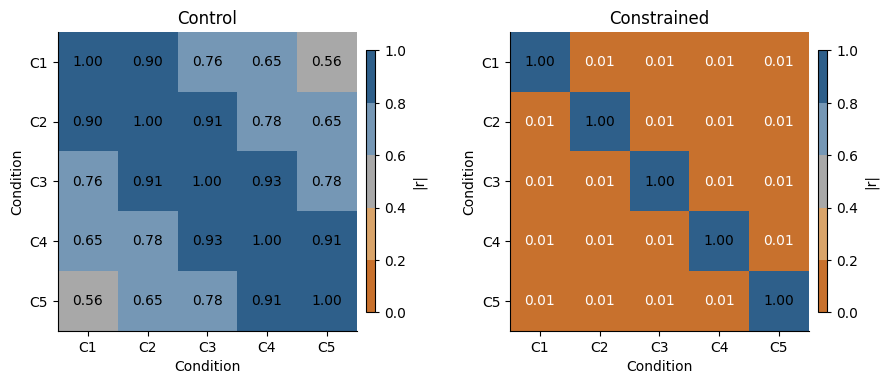

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.subplots_adjust(wspace=0.4)
plot_rsm(RSM["Control"], title="Control", ax=axes[0], cbar_label="|r|")
plot_rsm(RSM["Constrained"], title="Constrained", ax=axes[1], cbar_label="|r|")
fig.savefig(FIGURES / f"rsm_seed{SEED_FIG}.png", dpi=200, bbox_inches="tight")
plt.show()

## **5. Boxplot — Epochs**

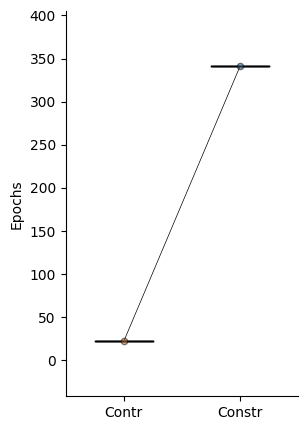

Control     : 22.0  (n = 1)
Constrained : 341.0  (n = 1)
one seed: no test


In [12]:
EPOCHS = np.array([[ck["stop_epoch"] for ck in CKPTS[c]] for c in CONDS], dtype=float)

fig, ax = plt.subplots(figsize=(3, 5))
stat = paired_boxplot(ax, EPOCHS, "Epochs")
plt.show()
for c, row in zip(CONDS, EPOCHS):
    sd = f" +/- {row.std(ddof=1):.1f}" if len(row) > 1 else ""
    print(f"{LAB[c]:12s}: {row.mean():.1f}{sd}  (n = {len(row)})")
print(f"paired t = {stat['t']:.3f}, p = {stat['p']:.3g}" if len(RUN_SEEDS) > 1 else "one seed: no test")

## **6. Boxplot — Correlation**

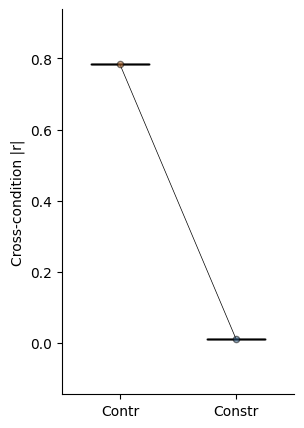

Control     : 0.7836  (n = 1)
Constrained : 0.0105  (n = 1)
one seed: no test


In [13]:
def cross_condition_r(c, s):
    r = R[c] if s == SEED_FIG else extract(D, IDX, MODELS_DIR, s, c)
    _, act = plot_sorted_averaged_activations(None, r["labels"], r["hidden"])
    return offdiag_mean_abs(compute_rsm(act))

CORRS = np.array([[cross_condition_r(c, s) for s in RUN_SEEDS] for c in CONDS])

fig, ax = plt.subplots(figsize=(3, 5))
stat = paired_boxplot(ax, CORRS, "Cross-condition |r|")
plt.show()
for c, row in zip(CONDS, CORRS):
    sd = f" +/- {row.std(ddof=1):.4f}" if len(row) > 1 else ""
    print(f"{LAB[c]:12s}: {row.mean():.4f}{sd}  (n = {len(row)})")
print(f"paired t = {stat['t']:.3f}, p = {stat['p']:.3g}" if len(RUN_SEEDS) > 1 else "one seed: no test")

### **Epochs**

In [14]:
import pickle
file_path = DATA / "Epochs.pkl"
with open(file_path, "rb") as f:
    data = pickle.load(f)

data1, data2 = data['std'], data['con']
data = np.array([data1, data2])

In [15]:
print("Model std:")
print("Mean:", np.mean(data1))
print("Standard deviation:", np.std(data1, ddof=1))

print("\nModel con:")
print("Mean:", np.mean(data2))
print("Standard deviation:", np.std(data2, ddof=1))

Model std:
Mean: 20.3
Standard deviation: 2.1628170930011117

Model con:
Mean: 347.1
Standard deviation: 18.48392695169388


t = -54.3861541811648
p = 1.2080303744847382e-12


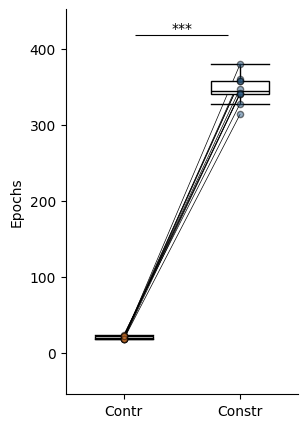

In [16]:
fig, ax = plt.subplots(figsize=(3, 5))
padding = 0.2 * (np.max(data) - np.min(data))

boxplot_with_lines(ax, data, xlabel=MODEL_LABELS_SHORT, ylabel="Epochs", colours=PAIR,
                   ymin=np.min(data) - padding, ymax=np.max(data) + padding,
                   use_legend=False)
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)


print(f"t = {stat['t']}")
print(f"p = {stat['p']}")

### **Correlation**

In [17]:
import pickle
file_path = DATA / "Correlations.pkl"
with open(file_path, "rb") as f:
    data = pickle.load(f)
data1, data2 = data['std'], data['con']
data = np.array([data1, data2])

In [18]:
print("Model std:")
print("Mean:", np.mean(data1))
print("Standard deviation:", np.std(data1, ddof=1))

print("\nModel con:")
print("Mean:", np.mean(data2))
print("Standard deviation:", np.std(data2, ddof=1))

Model std:
Mean: 0.7605088033247972
Standard deviation: 0.02984376916761711

Model con:
Mean: 0.012518462208405162
Standard deviation: 0.0018761872706289894


t = 77.37027757297035
p = 5.0937105724917884e-14


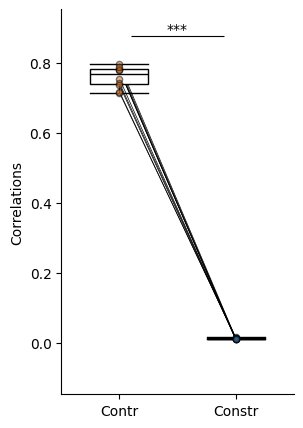

In [19]:
fig, ax = plt.subplots(figsize=(3, 5))
padding = 0.2 * (np.max(data) - np.min(data))

boxplot_with_lines(ax, data, xlabel=MODEL_LABELS_SHORT, ylabel="Correlations", colours=PAIR,
                   ymin=np.min(data) - padding, ymax=np.max(data) + padding,
                   use_legend=False)
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)


print(f"t = {stat['t']}")
print(f"p = {stat['p']}")


Correlation:
t = 77.37027757297035
p = 5.0937105724917884e-14
Epochs :
t = -54.3861541811648
p = 1.2080303744847382e-12


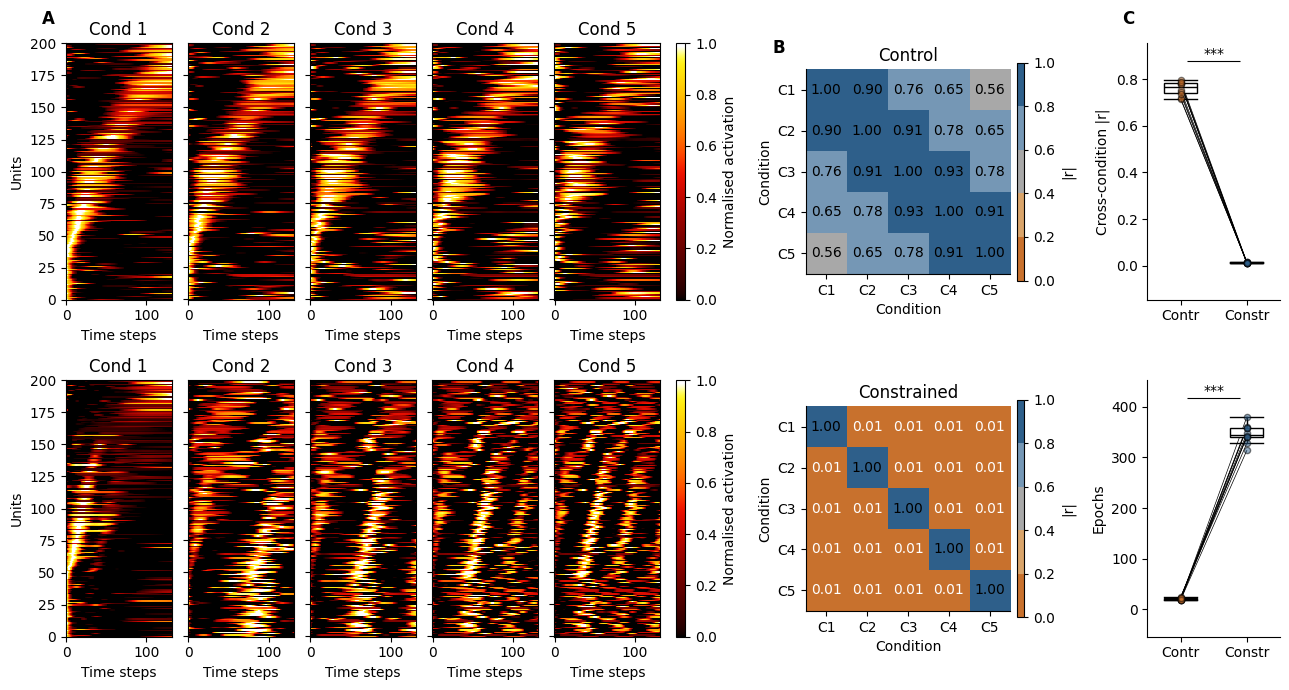

In [20]:
COLORS= ["#c8712d", "#d9a46a", "#a8a8a8", "#7597b5", "#2e5f8a"]
PAIR= [COLORS[0], COLORS[-1]]
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
################################
################################




from matplotlib import gridspec
gs  = gridspec.GridSpec(2, 6)
fig = plt.figure(tight_layout=True, figsize=[13, 7])
fig.subplots_adjust(hspace=0.5)
################################
################################



ratios= [0.12, 0.12, 0.12, 0.12, 0.12, 0.01, 0.1, 0.25, 0.1, 0.15]
row= gs[0,:].subgridspec(1, len(ratios), width_ratios= ratios, wspace= 0.15)
################################
################################



################################
################################
seed=SEEDS[1] 
cond=CONDS[0]
K=5
vmin, vmax= 0.0, 0.99
Labels, average_act_c = plot_sorted_averaged_activations(None, LABELS, HIDDEN["Control"], vmin=vmin, vmax=vmax, )

order, clim = None, (0.0, 0.99)
for k in range(K):
    ax = fig.add_subplot(row[0, k])
    if k==0:
        panel_letter(ax, "A")
        ax.set_ylim(0, 200)
        ax.set_yticks([0, 25, 50, 75, 100, 125, 150, 175, 200])
        ax.invert_yaxis()
    order, clim, im = plot_activation_heatmap(
        ax, average_act_c, k, sort_order=order, clim=clim, title= f'Cond {k+1}',
        show_ylabel=(k == 0), colorbar=False, despine=False)
    # im.remove()
cax = fig.add_subplot(row[0, K])
cbar = fig.colorbar(im, cax=cax)
# cbar.solids.set_visible(False)
cax.set_yticks([])
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar.set_label("Normalised activation")


################################
################################




ax = fig.add_subplot(row[0, 7])
######## Control RSM 
RSM = {name: compute_rsm(ACT[name]) for name in ACT}
plot_rsm(RSM["Control"], title="Control", ax=ax, cbar_label="|r|",cmap=cmap)
panel_letter(ax, "B")
################################
################################





import pickle
file_path = DATA / "Correlations.pkl"
with open(file_path, "rb") as f:
    data = pickle.load(f)
data1, data2 = data['std'], data['con']
data = np.array([data1, data2])

ax = fig.add_subplot(row[0, 9])
padding = 0.2 * (data.max() - data.min())
boxplot_with_lines(ax, data, xlabel=["Contr", "Constr"], ylabel="Cross-condition |r|", colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding,
                   use_legend=False)
panel_letter(ax, "C")
########
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
########
print('\nCorrelation:')
print(f"t = {stat['t']}")
print(f"p = {stat['p']}")
################################
################################







ratios= [0.12, 0.12, 0.12, 0.12, 0.12, 0.01, 0.1, 0.25, 0.1, 0.15]
row= gs[1,:].subgridspec(1, len(ratios), width_ratios= ratios, wspace= 0.15)
################################
################################



################################
################################
seed=SEEDS[1] 
cond=CONDS[1]
vmin, vmax= 0.0, 0.99
Labels, average_act_p = plot_sorted_averaged_activations(None, LABELS, HIDDEN["Constrained"], vmin=vmin, vmax=vmax,)
K=5
order, clim = None, (0.0, 0.99)
for k in range(K):
    ax = fig.add_subplot(row[0, k])
    if k==0:
        # panel_letter(ax, "B")
        ax.set_ylim(0, 200)
        ax.set_yticks([0, 25, 50, 75, 100, 125, 150, 175, 200])
        ax.invert_yaxis()
    order, clim, im = plot_activation_heatmap(
        ax, average_act_p, k, sort_order=order, clim=clim, title= f'Cond {k+1}',
        show_ylabel=(k == 0), colorbar=False, despine=False)
    # im.remove()
cax = fig.add_subplot(row[0, K])
cbar = fig.colorbar(im, cax=cax)
# cbar.solids.set_visible(False)
cax.set_yticks([])
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar.set_label("Normalised activation")

################################
################################



ax = fig.add_subplot(row[0, 7])
######## Constrained RMS 
plot_rsm(RSM["Constrained"], title="Constrained", ax=ax, cbar_label="|r|", cmap= cmap)
################################
################################




import pickle
file_path = DATA / "Epochs.pkl"
with open(file_path, "rb") as f:
    data = pickle.load(f)

data1, data2 = data['std'], data['con']
data = np.array([data1, data2])


ax = fig.add_subplot(row[0, 9])
padding = 0.2 * (data.max() - data.min())
boxplot_with_lines(ax, data, xlabel=["Contr", "Constr"], ylabel="Epochs", colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding, use_legend=False)
########
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
########
print("Epochs :")
print(f"t = {stat['t']}")
print(f"p = {stat['p']}")
################################
################################

plt.savefig(FIGURES / "ED Fig 5.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()
